# Trabalho Final — Avaliação de Políticas Públicas com Dados (APPD)

**Programa:** Mestrado Profissional em Administração Pública — IDP
**Professor:** Hélio Bomfim de Macêdo Filho
**Integrantes:** [PREENCHER: nomes completos]
**Política avaliada:** Programa Academia da Saúde (Portaria GM/MS nº 719/2011; Portaria GM/MS nº 2.681/2013)

**Pergunta causal:** a implantação do primeiro polo do Programa Academia da Saúde reduziu as internações por doenças cardiovasculares e metabólicas sensíveis à atividade física (doenças hipertensivas, AVC e diabetes) nos municípios que o adotaram?

**Estimando:** ATT — efeito médio sobre os municípios que implantaram ao menos um polo.
**Unidade de análise:** município × ano, 2008–2024.
**Métodos:** escore de propensão (Módulo 03) e diferenças-em-diferenças com estudo de eventos, TWFE e Callaway & Sant'Anna (Módulo 04).

> **Declaração de uso de IA (versão preliminar, a atualizar na Fase 8).** Este caderno foi desenvolvido com apoio do Claude Code (Anthropic), modelo [PREENCHER: nome e versão], para gerar e depurar código. Os autores revisaram cada célula, reexecutaram integralmente o caderno e assumem responsabilidade pelo conteúdo. Prompts e saídas relevantes estão em `docs/ia/`.

**Caderno 02 — análise:** painel, descritiva, escore de propensão, DiD, robustez e síntese.

**Localização do repositório.** Garante que o caderno rode a partir de `notebooks/`, inclusive quando aberto isolado (ex.: Google Colab), caso em que o repositório público é clonado. Todos os caminhos seguintes são relativos à raiz.

In [1]:
# Localiza a raiz do repositório (pasta com requirements.txt e src/appd).
# Se o caderno foi aberto isolado (ex.: Google Colab), clona o repositório
# público na pasta atual. Depois disso, tudo usa caminhos relativos à raiz.
import os
import subprocess
import sys
from pathlib import Path

URL_REPOSITORIO = "https://github.com/bsousa7/APPD_26.git"


def localizar_raiz():
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if (pasta / "requirements.txt").exists() and (pasta / "src" / "appd").exists():
            return pasta
    return None


raiz = localizar_raiz()
if raiz is not None and "google.colab" in sys.modules and (raiz / ".git").exists():
    # No Colab, a cópia clonada pode estar desatualizada: atualiza sempre.
    subprocess.run(["git", "-C", str(raiz), "pull", "--ff-only", "-q"], check=True)
if raiz is None:
    copia = Path("APPD_26")
    if (copia / ".git").exists():
        subprocess.run(["git", "-C", str(copia), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", URL_REPOSITORIO, str(copia)], check=True)
    os.chdir(copia)
    if localizar_raiz() is None:
        raise RuntimeError(
            f"A cópia em {Path.cwd()} não tem requirements.txt e src/appd. "
            "Apague a pasta APPD_26 e execute esta célula de novo."
        )
os.chdir(localizar_raiz() / "notebooks")
versao = subprocess.run(["git", "log", "-1", "--format=%h %cs"], capture_output=True, text=True).stdout.strip()
print(f"Pasta de trabalho: {Path.cwd().parent.name}/notebooks | versão do repositório: {versao}")

Pasta de trabalho: APPD_26/notebooks | versão do repositório: 2180820 2026-11-22


## 1. Identificação, pergunta e DAG

### 1.1 Pergunta, estimando e hipóteses

- **Tratamento (D):** ano do primeiro estabelecimento tipo 74 ("Polo Academia da Saúde") no CNES do município; coorte `g` = esse ano, `g = 0` para os nunca tratados.
- **Período e coortes:** painel 2008–2024; pré-tratamento 2008–2013; coortes a partir de 2014–2015, porque o tipo 74 só existe no CNES desde a Portaria SAS/MS nº 24/2014 (decisão registrada em `docs/decisoes.md`). Amostra do escore de propensão: coortes 2014–2015 contra nunca tratados. Robustez R7: coortes a partir de 2015, excluindo a coorte 2014, que pode incluir polos implantados entre 2011 e 2013 e cadastrados só em 2014.
- **Desfecho principal (Y):** internações SUS por doenças hipertensivas, AVC e diabetes (CID-10 I10–I15, I60–I69, E10–E14) por 10 mil habitantes, por município de residência.
- **Desfecho placebo:** internações por apendicite (K35–K38).
- **Estimando:** ATT.
- **Mecanismo:** polo → práticas corporais orientadas → mais atividade física → melhor controle de pressão e glicemia → menos internações. O efeito esperado é **defasado**, o que motiva o estudo de eventos.

### 1.2 DAG

**O que:** codifica as hipóteses causais em um grafo acíclico dirigido.
**Por quê:** justificar quais variáveis entram como controles (confundidores) e quais **não** podem entrar (mediadores, por sobrecontrole; colisores, por viés de seleção).

Arestas (a revisar pelos autores):
- Cada **confundidor** (porte, PIB per capita, cobertura de APS/ESF/NASF, % de idosos, taxa de internação pré-tratamento, leitos SUS, UF/região) afeta a adesão ao programa e as internações.
- **D → Atividade física → Controle de PA e glicemia → Y:** canal principal (mediadores, não controlados).
- **D → Y:** canais diretos não modelados (por exemplo, educação em saúde).
- **D → Atendimentos AB pós ← Y:** colisor; controlar por ele abriria um caminho espúrio.
- **Habilitação de investimento → D:** afeta só o momento da implantação.
- **Porte → Leitos** e **PIB → Cobertura APS:** relações entre confundidores.

In [2]:
# Célula autossuficiente: a seção 1 vem antes da preparação do ambiente (seção 2).
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

DIR_FIG = Path("..") / "outputs" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

PAPEL = {
    "Polo AS (D)": "tratamento",
    "Internações CV/DM (Y)": "desfecho",
    "Porte populacional": "confundidor",
    "PIB per capita 2010": "confundidor",
    "Cobertura APS/ESF/NASF 2010": "confundidor",
    "% 60+ anos": "confundidor",
    "Taxa pré 2008–2010": "confundidor",
    "Leitos SUS 2010": "confundidor",
    "UF / região": "confundidor",
    "Atividade física": "mediador",
    "Controle PA e glicemia": "mediador",
    "Atendimentos AB pós": "colisor",
    "Habilitação investimento": "so_D",
}
D, Y = "Polo AS (D)", "Internações CV/DM (Y)"
CONFUNDIDORES = [v for v, p in PAPEL.items() if p == "confundidor"]

dag = nx.DiGraph()
dag.add_nodes_from(PAPEL)
dag.add_edges_from((c, D) for c in CONFUNDIDORES)          # afetam a adesão
dag.add_edges_from((c, Y) for c in CONFUNDIDORES)          # afetam as internações
dag.add_edges_from([
    (D, "Atividade física"),                                # mecanismo
    ("Atividade física", "Controle PA e glicemia"),
    ("Controle PA e glicemia", Y),
    (D, Y),                                                 # outros canais (educação em saúde)
    (D, "Atendimentos AB pós"), (Y, "Atendimentos AB pós"), # colisor
    ("Habilitação investimento", D),                        # só afeta o momento de D
    ("Porte populacional", "Leitos SUS 2010"),
    ("PIB per capita 2010", "Cobertura APS/ESF/NASF 2010"),
])
assert nx.is_directed_acyclic_graph(dag)
print(dag.number_of_nodes(), "nós,", dag.number_of_edges(), "arestas")

13 nós, 23 arestas


O grafo é acíclico, condição necessária para aplicar o critério de backdoor.

### 1.3 Teste do critério de backdoor

**O que:** verifica, com `nx.is_d_separator`, se cada conjunto de controles bloqueia todos os caminhos de porta dos fundos entre D e Y sem incluir descendentes de D.
**Por quê:** fundamenta a escolha das covariáveis X do escore de propensão e mostra por que mediador e colisor ficam de fora.

In [3]:
def satisfaz_backdoor(g: nx.DiGraph, x: str, y: str, z: set) -> bool:
    """Critério de backdoor: Z não contém descendentes de X e d-separa X de Y
    no grafo sem as arestas que saem de X."""
    if z & nx.descendants(g, x):
        return False
    g_bd = g.copy()
    g_bd.remove_edges_from(list(g.out_edges(x)))
    return nx.is_d_separator(g_bd, {x}, {y}, z)

testes = {
    "Confundidores": set(CONFUNDIDORES),
    "Nenhum controle": set(),
    "Confundidores + mediador": set(CONFUNDIDORES) | {"Atividade física"},
    "Confundidores + colisor": set(CONFUNDIDORES) | {"Atendimentos AB pós"},
    "Confundidores sem taxa pré": set(CONFUNDIDORES) - {"Taxa pré 2008–2010"},
}
pd.Series({k: satisfaz_backdoor(dag, D, Y, v) for k, v in testes.items()},
          name="satisfaz backdoor").to_frame()

,satisfaz backdoor
Confundidores,True
Nenhum controle,False
Confundidores + mediador,False
Confundidores + colisor,False
Confundidores sem taxa pré,False


**Resultado esperado:** apenas o conjunto completo de confundidores satisfaz o critério. Sem controles, ou sem a taxa pré-tratamento, permanecem caminhos abertos; ao incluir o mediador ou o colisor, o conjunto contém descendentes de D e viola o critério. [Os autores devem confirmar a leitura após executar.]

### 1.4 Figura do DAG
Exporta `outputs/figuras/fig01_dag.png`, usada na seção 3 do artigo.

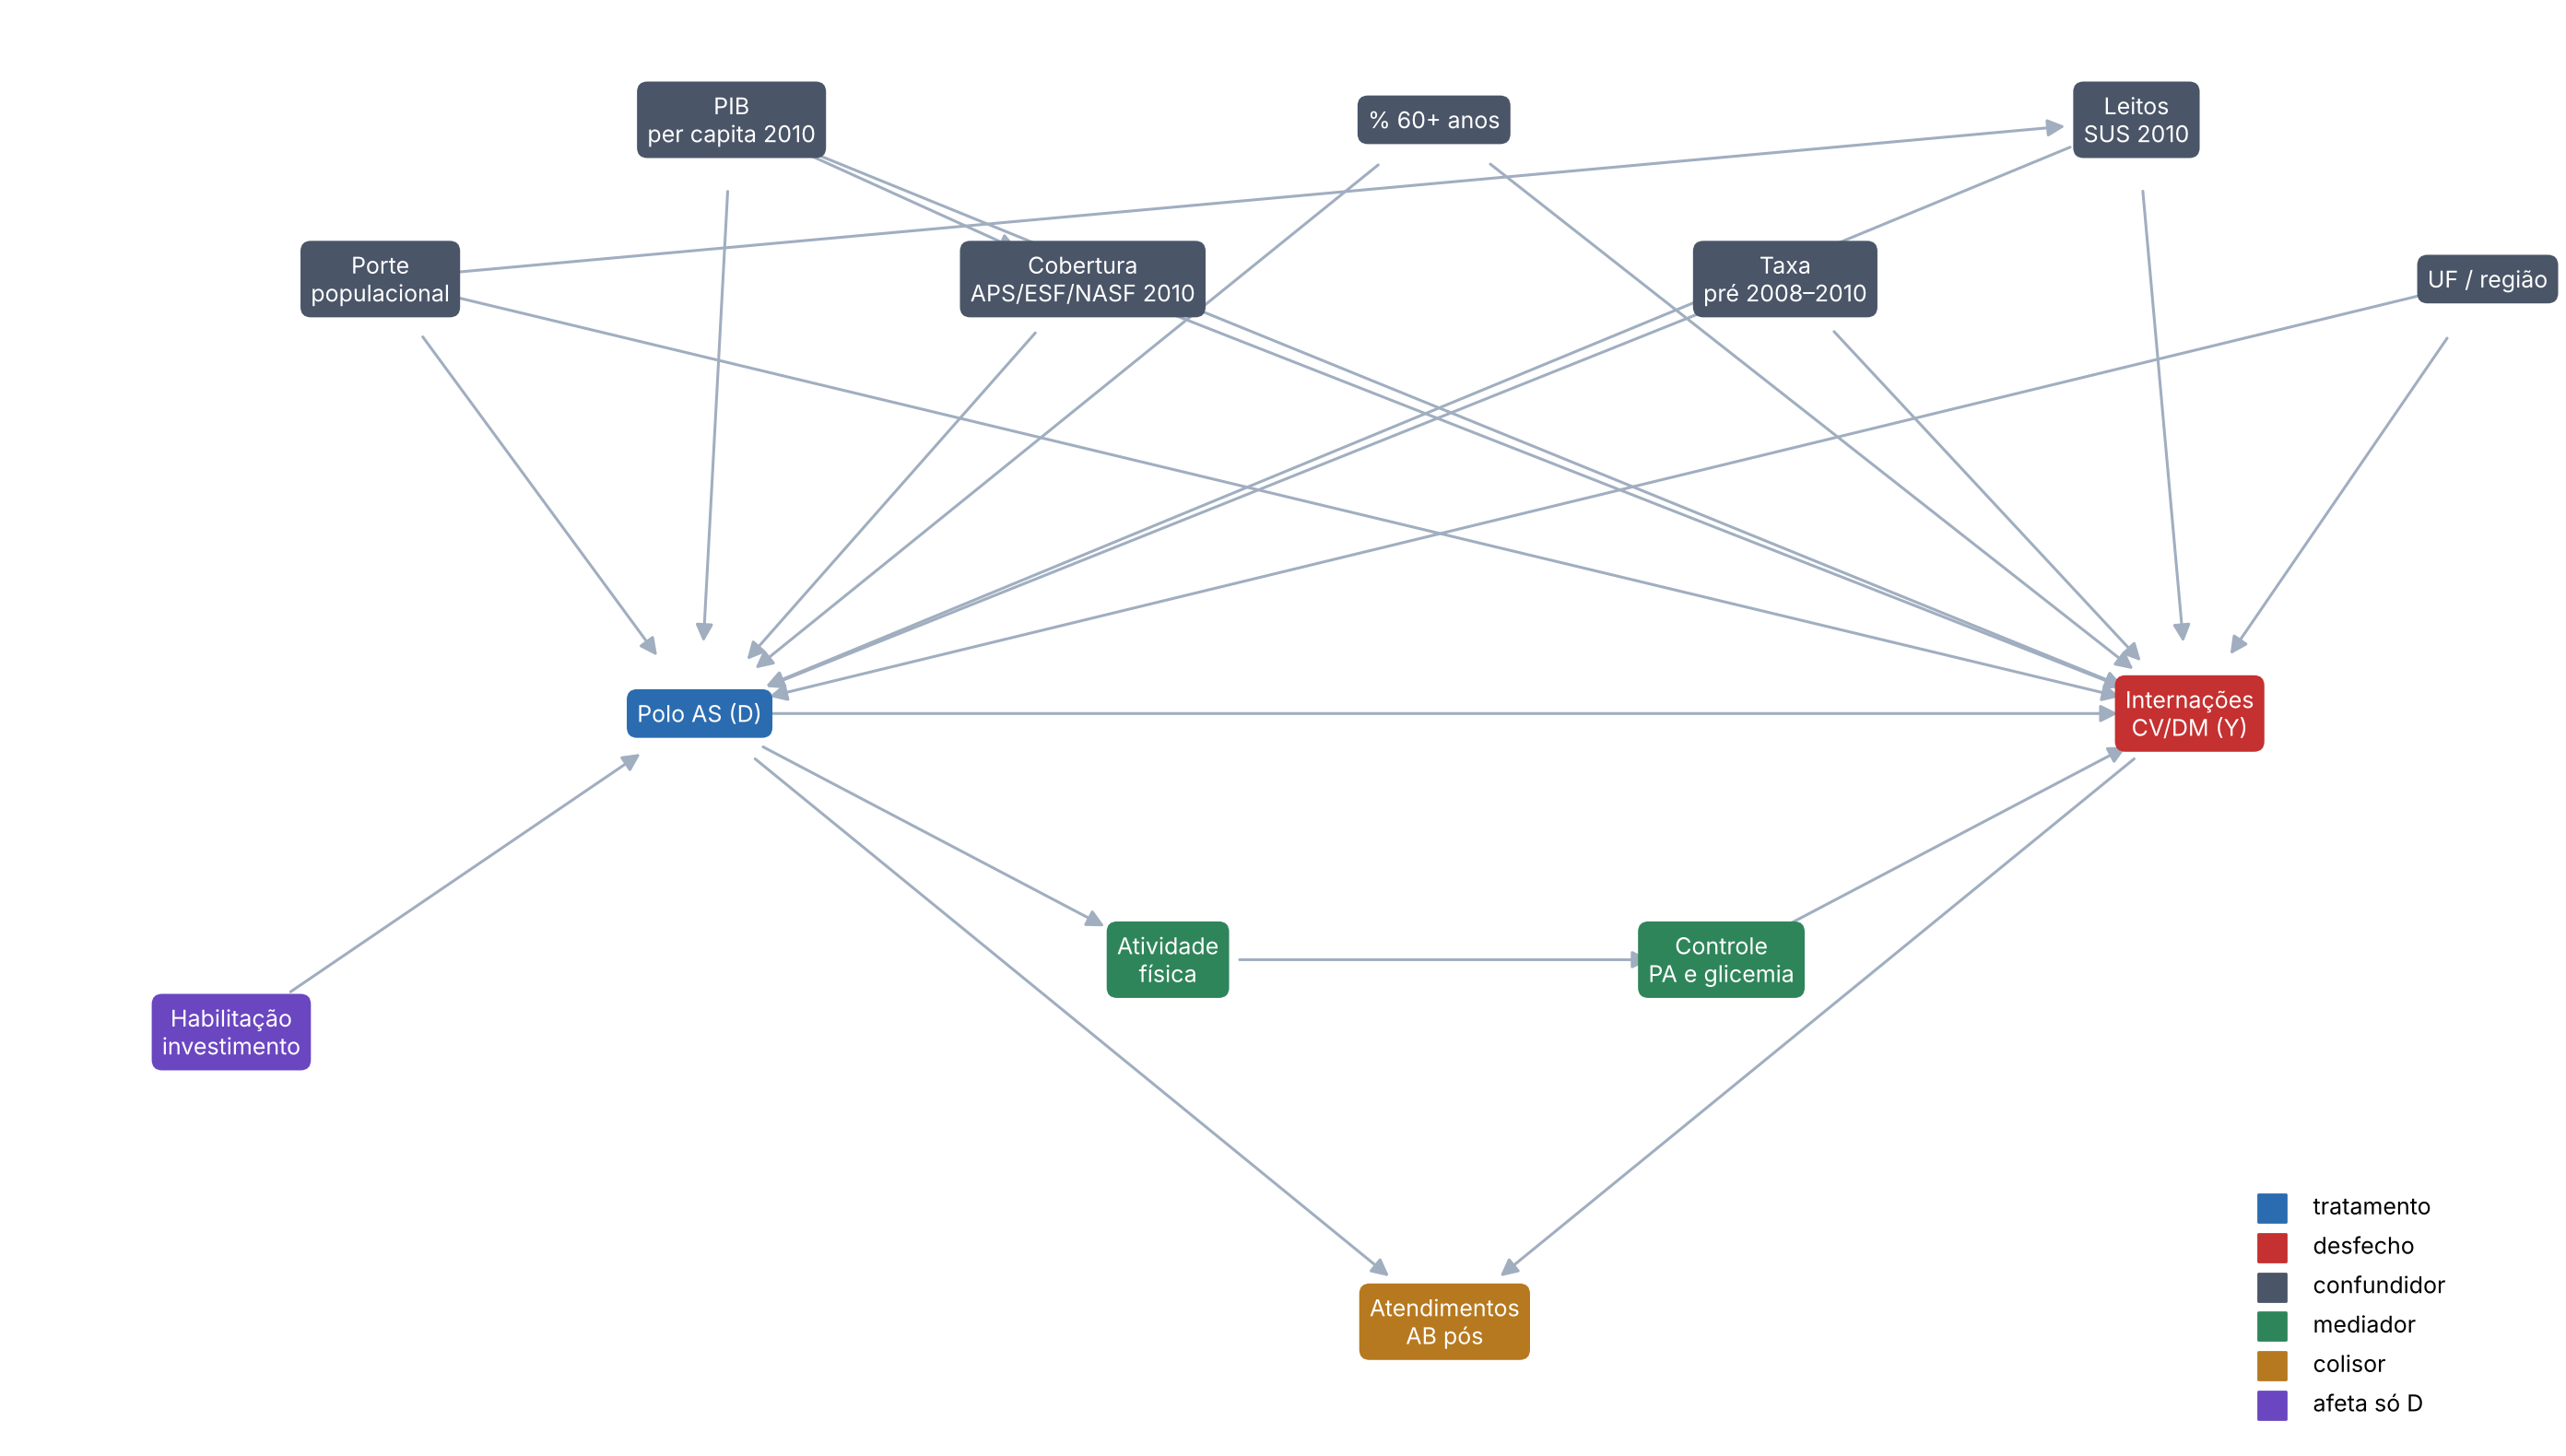

In [4]:
CORES = {"tratamento": "#2b6cb0", "desfecho": "#c53030", "confundidor": "#4a5568",
         "mediador": "#2f855a", "colisor": "#b7791f", "so_D": "#6b46c1"}
pos = {D: (0, 0), Y: (7, 0), "Atividade física": (2.2, -1.7), "Controle PA e glicemia": (4.8, -1.7),
       "Atendimentos AB pós": (3.5, -4.2), "Habilitação investimento": (-2.2, -2.2)}
for i, c in enumerate(CONFUNDIDORES):
    pos[c] = (-1.5 + i * 1.65, 3.0 + (i % 2) * 1.1)
rotulo = lambda v: v.replace(" ", "\n", 1) if len(v) > 12 else v

fig, ax = plt.subplots(figsize=(14, 8))
nx.draw_networkx_edges(dag, pos, ax=ax, arrowsize=14, edge_color="#a0aec0", width=1.1,
                       min_source_margin=28, min_target_margin=28)
for v, (x, y) in pos.items():
    ax.text(x, y, rotulo(v), ha="center", va="center", fontsize=9, color="white",
            bbox=dict(boxstyle="round,pad=0.45", fc=CORES[PAPEL[v]], ec="none"))
for papel, cor in CORES.items():
    ax.scatter([], [], s=120, marker="s", color=cor, label=papel.replace("so_D", "afeta só D"))
ax.legend(loc="lower right", fontsize=9, frameon=False)
ax.set_xlim(-3.2, 8.3); ax.set_ylim(-5, 4.8)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(DIR_FIG / "fig01_dag.png", dpi=200, bbox_inches="tight")
plt.show()

A figura distingue os papéis das variáveis por cor.

### 1.5 SUTVA

- **Transbordamento:** moradores de municípios vizinhos podem usar o polo, contaminando os controles. Mitigação: desfecho por município de **residência** (`MUNIC_RES`) e, na robustez, exclusão de controles vizinhos de tratados, se houver tempo.
- **Versões do tratamento:** há polos de modalidades diferentes (básica, intermediária, ampliada) e polos "similares". Mitigação: tratamento alternativo pelo incentivo de custeio (81.12/81.13) e discussão no artigo.

## 2. Preparação do ambiente

**O que:** instala as dependências com as versões fixadas em `requirements.txt`, importa as bibliotecas, define caminhos relativos à raiz do repositório e a semente aleatória.
**Por quê:** reprodutibilidade — qualquer pessoa deve conseguir rodar o caderno com "Restart & Run All" a partir de `notebooks/`.

In [5]:
# Escolhe o arquivo de requisitos conforme o ambiente:
# - Google Colab: requirements-colab.txt (só o que o Colab não traz, sem
#   substituir pandas, ipykernel etc., que o próprio Colab exige);
# - ambiente local: requirements.txt (todas as bibliotecas, versões fixadas).
# O caminho é calculado a partir de notebooks/ e passado já resolvido ao %pip.
import sys
from pathlib import Path

NO_COLAB = "google.colab" in sys.modules
nome = "requirements-colab.txt" if NO_COLAB else "requirements.txt"
ARQ_REQUISITOS = (Path.cwd().parent / nome).resolve()
if not ARQ_REQUISITOS.exists():
    raise FileNotFoundError(
        f"{nome} não encontrado a partir de {Path.cwd().name}/. "
        "Execute antes a célula 'Localização do repositório' (seção 1)."
    )
print("Instalando", nome)
%pip install -q -r {ARQ_REQUISITOS}

# Se o pip trocou a versão de uma biblioteca que já estava carregada (comum no
# Colab, que pré-carrega numpy e pandas), a sessão precisa ser reiniciada.
from importlib.metadata import version as versao_instalada

trocadas = [
    f"{nome} {sys.modules[nome].__version__} -> {versao_instalada(nome)}"
    for nome in ["numpy", "pandas", "scipy"]
    if nome in sys.modules and sys.modules[nome].__version__ != versao_instalada(nome)
]
if trocadas:
    raise RuntimeError(
        "Bibliotecas atualizadas: " + "; ".join(trocadas) + ". Reinicie a sessão "
        "(Ambiente de execução > Reiniciar sessão) e execute TUDO de novo, desde a "
        "primeira célula de código. Na segunda execução esta célula passa direto."
    )
print("Dependências prontas.")

Instalando requirements.txt


Note: you may need to restart the kernel to use updated packages.
Dependências prontas.


In [6]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

RAIZ = Path("..")
if not (RAIZ / "src" / "appd").exists():
    raise RuntimeError(
        "Pasta de trabalho errada (comum após reiniciar a sessão do Colab). "
        "Execute o caderno desde a primeira célula de código (localização do repositório)."
    )
sys.path.insert(0, str(RAIZ / "src"))

DIR_RAW = RAIZ / "data" / "raw"
DIR_PROC = RAIZ / "data" / "processed"
DIR_DIC = DIR_PROC / "dicionarios"
DIR_FIG = RAIZ / "outputs" / "figuras"
DIR_TAB = RAIZ / "outputs" / "tabelas"
for d in (DIR_RAW, DIR_PROC, DIR_DIC, DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
np.random.seed(SEMENTE)
pd.set_option("display.max_columns", 30)
from importlib.metadata import version
print("Python", sys.version.split()[0], "|", ", ".join(
    f"{p} {version(p)}" for p in ["pandas", "numpy", "scipy", "statsmodels",
                                  "scikit-learn", "linearmodels", "differences", "pysus"]))

from appd import estimacao as est

Python 3.13.18 | pandas 2.3.3, numpy 2.4.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, linearmodels 7.1, differences 0.3.0, pysus 2.12.2


Ambiente pronto: caminhos, semente e funções auxiliares de `src/appd/estimacao.py` disponíveis para as seções seguintes.

## 3. Painel e validação
*Fase 4:* leitura de `data/processed/`, junção com população e covariáveis, taxas por 10 mil habitantes, definição das amostras DiD e PSM (com contagem de cada exclusão) e `assert` de painel balanceado, ausência de faltantes e D monotônico.

## 4. Análise descritiva
*Fase 4:* `tab01_descritiva`, `fig02_coortes`, `fig03_tendencias`. **Sem leitura causal nesta seção.**

## 5. Método 1 — escore de propensão
*Fase 5:* hipóteses de ignorabilidade e suporte comum; logit e gradient boosting calibrado; `fig04_suporte_comum`; vizinho mais próximo com caliper e IPW (pesos ATT); `tab02_balanceamento` e `fig05_loveplot`; ATT com bootstrap (1.000 réplicas, `SEMENTE`).

## 6. Método 2 — diferenças-em-diferenças
*Fase 6:* tendências paralelas e não antecipação; estudo de eventos (`fig06`); TWFE clusterizado (`tab03`); Goodman-Bacon (`fig07`); Callaway & Sant'Anna (`fig08`, `tab04`); placebos (`tab05`).

## 7. Robustez e poder
*Fase 6:* R1–R7 (`tab06_robustez`) e MDE (`tab07_mde`).

## 8. Síntese e exportação
*Fase 6:* `tab08_sintese` (estimativa, EP, IC 95%, N e nota de cada método), exportada em `.csv` e `.tex` com o mesmo nome-base usado no artigo.